# Step 7: final insights

All computation is in `src/insights.py`; this notebook calls it, shows the tables and charts, and writes `reports/insights/key_numbers.csv`. Reads `data/model/` (DQ headline numbers come from the generated Step 3/4 reports). Machines are the unit. Fault rates are pooled (total faults / total sessions x 100) with 95% bootstrap intervals (machines resampled within group, 2,000 resamples, fixed seed); continuous measures are machine-level medians. Return/Repair (RR) is a selected population; nothing here claims a cause. Filter Wash (13/1) as a 'maintenance alert' is our grouping, not the brief's.

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import pandas as pd
import matplotlib.pyplot as plt
import insights as ins
pd.set_option('display.width', 220, 'display.max_columns', 40, 'display.max_rows', 200)
R = ins.compute()
print('resamples', ins.N_BOOT, 'seed', ins.SEED)

resamples 2000 seed 20261011


## Counts and data quality headline numbers

In [2]:
display(R['machine_counts'])
display(R['dq_table'].round(1))
display(R['dq_extra'].round(2))

cohort,Normal,Return/Repair
machines in dim_machine,186,46
rate-eligible machines (>= 10 analysis sessions),158,36
machines with a valid motor runtime per day,54,36


,table,cohort,raw_rows,analysis_rows,pct_kept
0,clean_sessions,normal,40627,30832,75.9
1,clean_sessions,return_repair,6565,4641,70.7
2,faults,normal,11449,3674,32.1
3,faults,return_repair,19957,861,4.3
4,motor,normal,470,470,100.0
5,motor,return_repair,564,488,86.5
6,battery,normal,2766,551,19.9
7,battery,return_repair,32614,407,1.2


,cohort,exact_copy_rows,fault_raw,pct_exact_copy,empty_rows,battery_raw,pct_empty
0,normal,6406,11449,55.95,1516,2766,54.81
1,return_repair,18196,19957,91.18,32033,32614,98.22
2,all,24602,31406,78.34,33549,35380,94.82


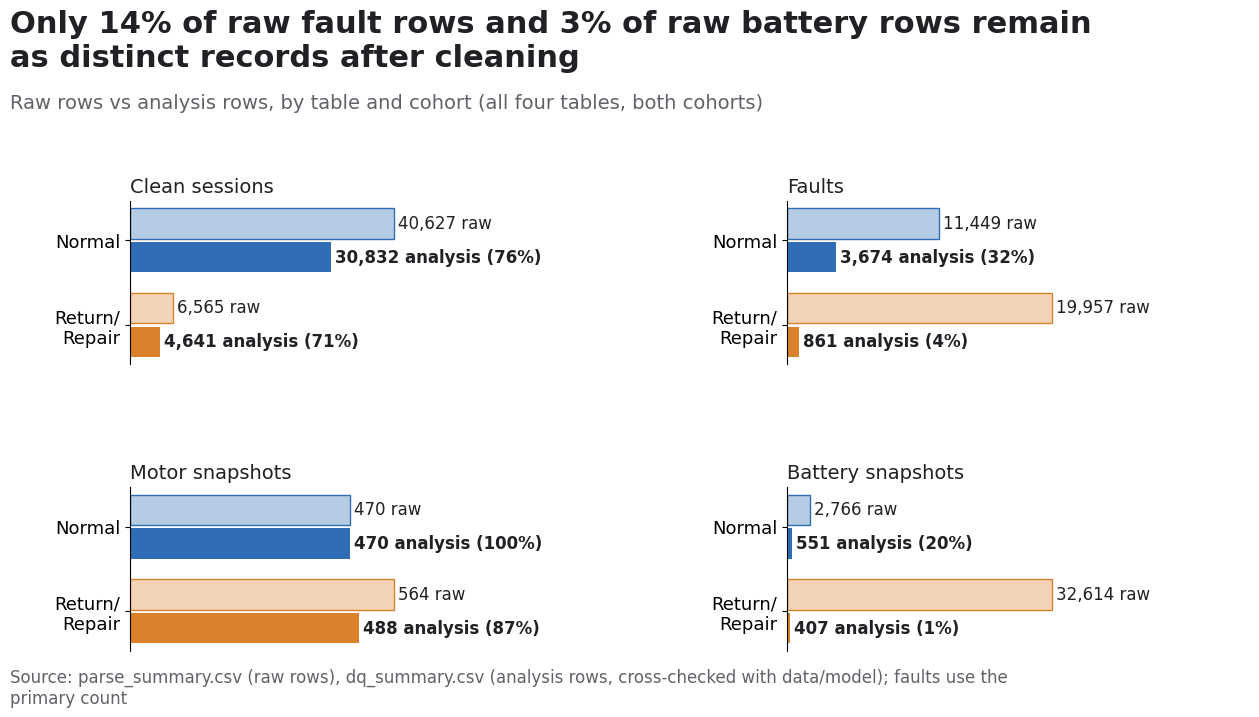

['01_dq_raw_vs_analysis_rows.png', '01_dq_raw_vs_analysis_rows.svg']


In [3]:
ch = ins.make_charts(R)
fig, paths = ch['dq']; display(fig); print([p.name for p in paths])

## Insight 1: model effect on fault counts (Filter Wash 13/1 as maintenance alert, our grouping)

In [4]:
display(R['i1_rates'].round(2))
display(R['i1_diffs'].round(2))
print('Filter Wash share of Normal SV50 vs SV53 gap: %.1f%%' % (100*R['i1_fw_share']))

,group,measure,rate,lo,hi,machines,faults,sessions
0,Normal SV50,all fault types,16.53,12.65,21.71,99,3158,19099
1,Normal SV50,Filter Wash 13/1 (maintenance alert; our group...,11.44,8.70,15.01,99,2185,19099
2,Normal SV50,all other faults (excl. 13/1),5.09,3.42,7.55,99,973,19099
3,Normal SV50,"12/1 inlet blocked, motor still running",3.59,2.47,5.19,99,686,19099
4,Normal SV50,12/2 inlet blocked and in error,1.50,0.89,2.44,99,286,19099
5,Normal SV50,11/2 Battery Temperature HOT,0.01,0.00,0.02,99,1,19099
6,Normal SV53,all fault types,4.29,1.99,7.54,59,500,11666
7,Normal SV53,Filter Wash 13/1 (maintenance alert; our group...,1.47,0.52,2.96,59,172,11666
8,Normal SV53,all other faults (excl. 13/1),2.81,1.19,5.27,59,328,11666
9,Normal SV53,"12/1 inlet blocked, motor still running",1.71,0.36,3.86,59,199,11666


,comparison,measure,a,b,diff,ratio,lo,hi,n_a,n_b
0,Normal: SV53 minus SV50,all fault types,16.53,4.29,-12.25,0.26,-17.88,-7.26,99,59
1,Normal: SV53 minus SV50,Filter Wash 13/1 (maintenance alert; our group...,11.44,1.47,-9.97,0.13,-13.54,-6.89,99,59
2,Normal: SV53 minus SV50,all other faults (excl. 13/1),5.09,2.81,-2.28,0.55,-5.33,0.71,99,59
3,SV53: Return/Repair minus Normal,all fault types,4.29,18.68,14.39,4.36,2.43,34.35,59,36
4,SV53: Return/Repair minus Normal,Filter Wash 13/1 (maintenance alert; our group...,1.47,5.59,4.11,3.79,0.18,9.74,59,36
5,SV53: Return/Repair minus Normal,all other faults (excl. 13/1),2.81,13.09,10.28,4.66,1.66,24.74,59,36


Filter Wash share of Normal SV50 vs SV53 gap: 81.4%


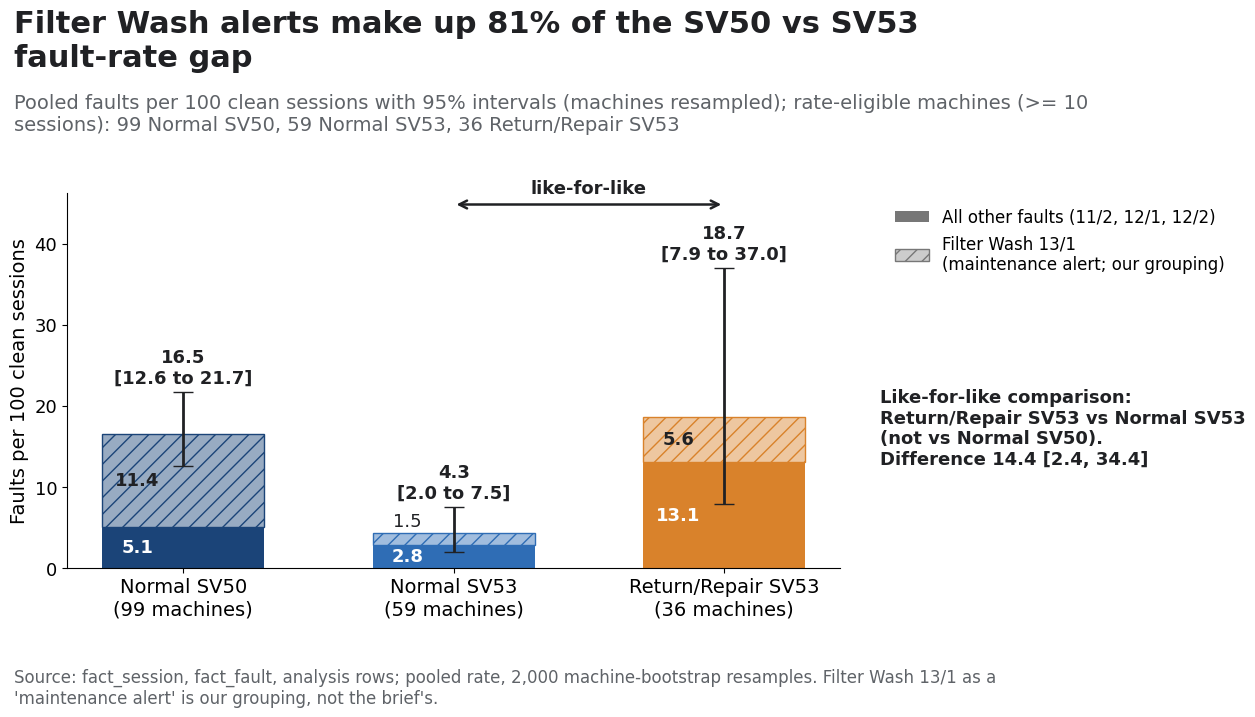

['02_insight1_model_effect_fault_rate.png', '02_insight1_model_effect_fault_rate.svg']


In [5]:
fig, paths = ch['insight1']; display(fig); print([p.name for p in paths])

## Insight 2: airway blockage (type 12), SV53 only

In [6]:
display(R['i2_rates'].round(2))
display(R['i2_hour'].round(3))
print('Machines per SV53 sub-model'); display(R['i2_mix'])
print('Region'); display(R['i2_region'])
print('Exposure sample machines:', R['exposure'].groupby('cohort').size().to_dict())

,subset,cohort,measure,col,rate,lo,hi,machines,faults,sessions
0,SV53,Normal,type 12 airway blockage (values 1+2),n_t12,2.81,1.19,5.27,59,328,11666
1,SV53,Normal,"12/1 inlet blocked, motor still running",n_t12_v1,1.71,0.36,3.86,59,199,11666
2,SV53,Normal,12/2 inlet blocked and in error,n_t12_v2,1.11,0.59,1.67,59,129,11666
3,SV53,Return/Repair,type 12 airway blockage (values 1+2),n_t12,13.09,5.13,26.66,36,602,4599
4,SV53,Return/Repair,"12/1 inlet blocked, motor still running",n_t12_v1,6.59,1.72,14.72,36,303,4599
5,SV53,Return/Repair,12/2 inlet blocked and in error,n_t12_v2,6.50,2.79,12.32,36,299,4599
6,"SV53, ROW-PROD only",Normal,type 12 airway blockage (values 1+2),n_t12,2.38,0.99,4.60,54,268,11260
7,"SV53, ROW-PROD only",Normal,"12/1 inlet blocked, motor still running",n_t12_v1,1.33,0.26,3.21,54,150,11260
8,"SV53, ROW-PROD only",Normal,12/2 inlet blocked and in error,n_t12_v2,1.05,0.54,1.59,54,118,11260
9,"SV53, ROW-PROD only",Return/Repair,type 12 airway blockage (values 1+2),n_t12,13.07,5.18,27.38,35,596,4559


,cohort,measure,col,rate,lo,hi,machines,faults,hours
0,Normal,type 12 airway blockage (values 1+2),n_t12_win,0.321,0.091,0.704,45,202,630.214
1,Normal,"12/1 inlet blocked, motor still running",n_t12_1_win,0.230,0.026,0.561,45,145,630.214
2,Normal,12/2 inlet blocked and in error,n_t12_2_win,0.090,0.048,0.151,45,57,630.214
3,Return/Repair,type 12 airway blockage (values 1+2),n_t12_win,1.732,0.582,3.561,30,522,301.370
4,Return/Repair,"12/1 inlet blocked, motor still running",n_t12_1_win,0.859,0.160,1.961,30,259,301.370
5,Return/Repair,12/2 inlet blocked and in error,n_t12_2_win,0.873,0.329,1.612,30,263,301.370


Machines per SV53 sub-model


cohort,Normal,Return/Repair,Total
model,,,
SV53-AA,2,0,2
SV53-AB,18,21,39
SV53-AC,4,2,6
SV53-AE,5,2,7
SV53-AF,30,11,41


Region


cohort,Normal,Return/Repair
region,,
CN-PROD,5,1
ROW-PROD,54,35


Exposure sample machines: {'normal': 45, 'return_repair': 30}


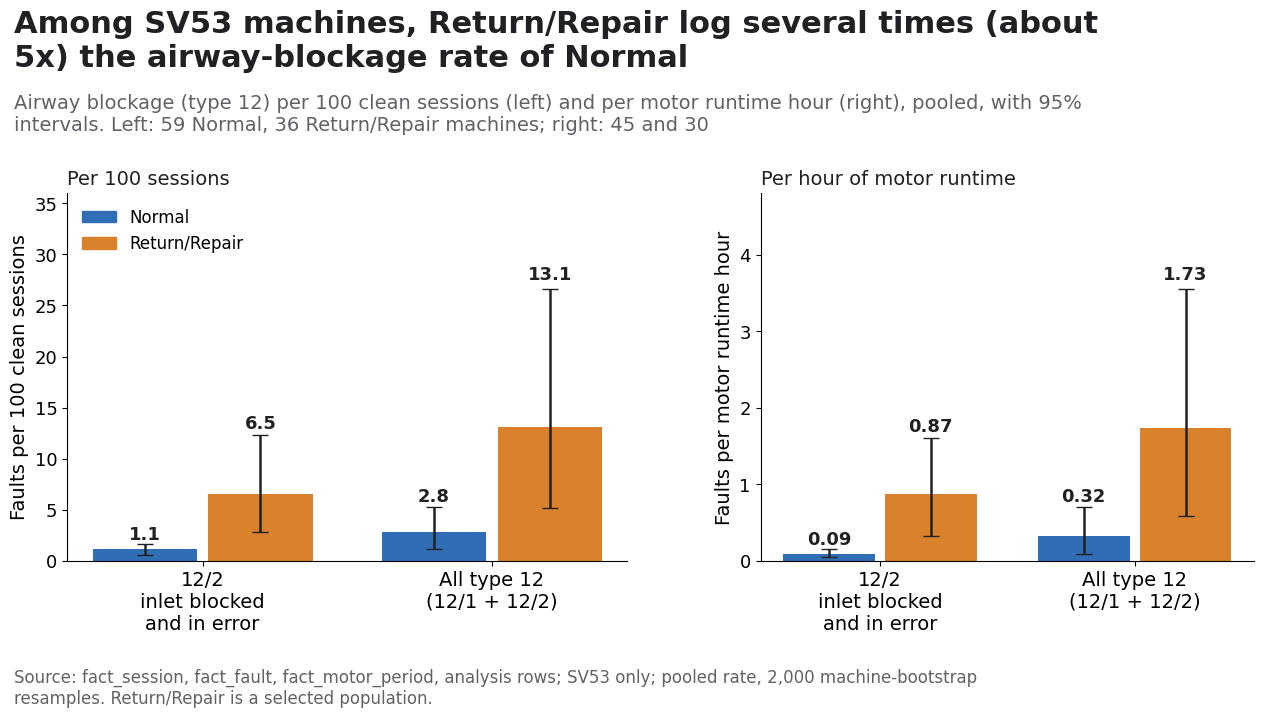

['03_insight2_airway_blockage_sv53.png', '03_insight2_airway_blockage_sv53.svg']


In [7]:
fig, paths = ch['insight2']; display(fig); print([p.name for p in paths])

## Insight 3: motor minutes per day

In [8]:
display(R['i3_medians'].round(2))
display(R['i3_variants'].round(3))
print('Common calendar months:', R['i3_common_months'][0], 'to', R['i3_common_months'][-1])
display(R['i3_mix'])

,cohort,median,lo,hi,machines
0,Normal,2.38,1.78,3.36,54
1,Return/Repair,4.87,3.08,6.38,36


,variant,n_normal,n_rr,normal,rr,diff,ratio,ci_lo,ci_hi
0,all valid periods,54,36,2.384,4.869,2.485,2.042,0.430,3.979
1,ROW-PROD only,49,35,2.460,5.049,2.589,2.052,0.291,4.074
2,SV53-AB only,15,22,1.714,4.212,2.498,2.458,-0.447,5.377
3,"SV53-AB, ROW-PROD only",14,22,1.619,4.212,2.593,2.602,-0.599,5.541
4,whole periods inside common months 2025-10 to ...,52,36,2.167,4.446,2.279,2.052,0.488,3.905
5,pro-rated to common months 2025-10 to 2026-05,54,36,2.288,4.869,2.581,2.128,0.544,3.957


Common calendar months: 2025-10 to 2026-05


cohort,Normal,Return/Repair,Total
model,,,
SV53-AA,2,0,2
SV53-AB,15,22,37
SV53-AC,4,2,6
SV53-AE,5,3,8
SV53-AF,28,9,37


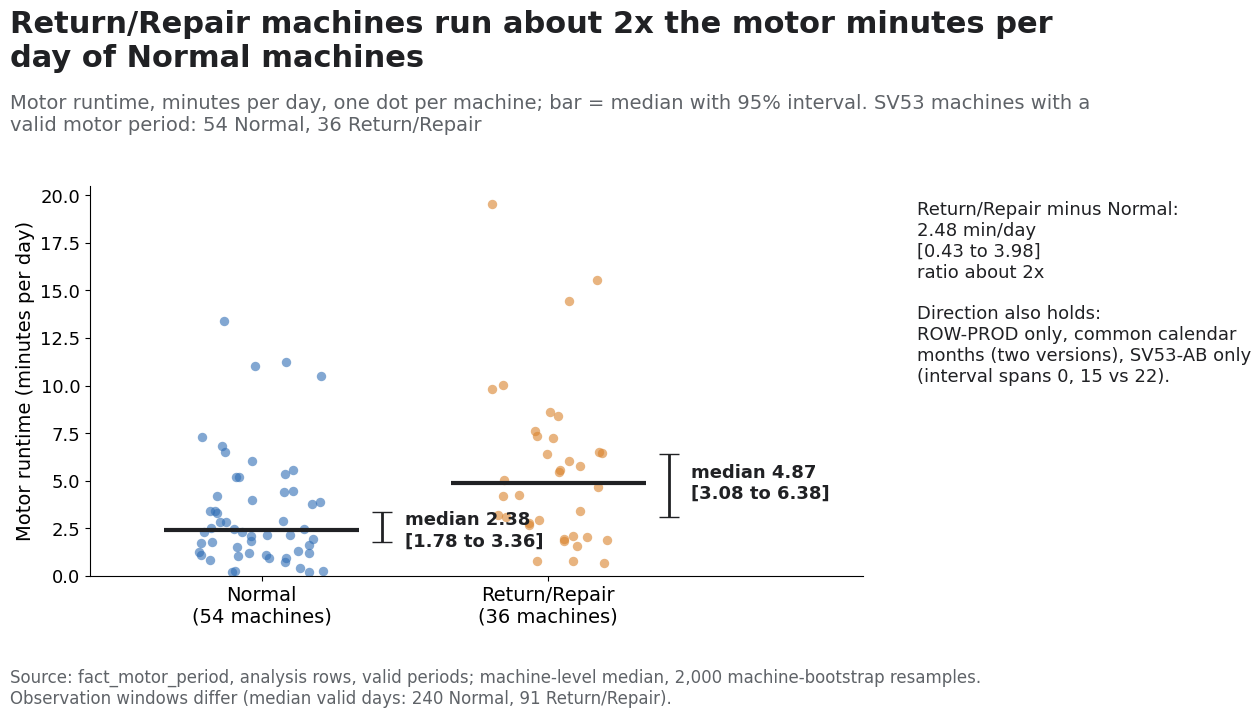

['04_insight3_motor_minutes_per_day.png', '04_insight3_motor_minutes_per_day.svg']


In [9]:
fig, paths = ch['insight3']; display(fig); print([p.name for p in paths])

## Write key numbers and check against Step 6 / 6b

In [10]:
p = ins.write_key_numbers(R)
print(p.name, len(R['key']), 'rows')
chk = R['step6_check']
print('Step 6 / 6b numbers repeated here:', len(chk), '; differ:', int((~chk.matches).sum()))
display(chk[~chk.matches])
R['key'].round(3)

key_numbers.csv 152 rows
Step 6 / 6b numbers repeated here: 61 ; differ: 0


,id,field,step6_printed,step7,matches,reference


,id,insight,metric,group,value,interval_low,interval_high,n_machines,n_events_or_sessions,n_denominator,denominator_unit,unit,script_or_cell,note
0,dq_raw_clean_sessions_normal,DQ,raw rows,clean_sessions / Normal,40627.000,NaN,NaN,NaN,NaN,NaN,,rows,src/insights.py:dq_numbers | reports/profiling...,column raw_rows_in
1,dq_analysis_clean_sessions_normal,DQ,analysis rows,clean_sessions / Normal,30832.000,NaN,NaN,NaN,NaN,NaN,,rows,src/insights.py:dq_numbers | reports/dq/dq_sum...,check is_analysis_row (faults: primary count);...
2,dq_pct_kept_clean_sessions_normal,DQ,analysis rows as % of raw rows,clean_sessions / Normal,75.890,NaN,NaN,NaN,30832.0,40627.000,raw rows,%,src/insights.py:dq_numbers | reports/dq/dq_sum...,
3,dq_raw_clean_sessions_return_repair,DQ,raw rows,clean_sessions / Return/Repair,6565.000,NaN,NaN,NaN,NaN,NaN,,rows,src/insights.py:dq_numbers | reports/profiling...,column raw_rows_in
4,dq_analysis_clean_sessions_return_repair,DQ,analysis rows,clean_sessions / Return/Repair,4641.000,NaN,NaN,NaN,NaN,NaN,,rows,src/insights.py:dq_numbers | reports/dq/dq_sum...,check is_analysis_row (faults: primary count);...
5,dq_pct_kept_clean_sessions_return_repair,DQ,analysis rows as % of raw rows,clean_sessions / Return/Repair,70.693,NaN,NaN,NaN,4641.0,6565.000,raw rows,%,src/insights.py:dq_numbers | reports/dq/dq_sum...,
6,dq_raw_faults_normal,DQ,raw rows,faults / Normal,11449.000,NaN,NaN,NaN,NaN,NaN,,rows,src/insights.py:dq_numbers | reports/profiling...,column raw_rows_in
7,dq_analysis_faults_normal,DQ,analysis rows,faults / Normal,3674.000,NaN,NaN,NaN,NaN,NaN,,rows,src/insights.py:dq_numbers | reports/dq/dq_sum...,check is_analysis_row (faults: primary count);...
8,dq_pct_kept_faults_normal,DQ,analysis rows as % of raw rows,faults / Normal,32.090,NaN,NaN,NaN,3674.0,11449.000,raw rows,%,src/insights.py:dq_numbers | reports/dq/dq_sum...,
9,dq_raw_faults_return_repair,DQ,raw rows,faults / Return/Repair,19957.000,NaN,NaN,NaN,NaN,NaN,,rows,src/insights.py:dq_numbers | reports/profiling...,column raw_rows_in
